# CXC102

In [71]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 
import datetime
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))
 
module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)

from src.utils.ds_helper import get_dataset_distribution
from src.utils.confusion_matrix import generate_confusion
from src.utils.roc_curve import generate_roc_curve
from src.utils.training_plots import plot_train_accuracy, plot_train_loss


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [46]:
# Load the TensorBoard notebook extension
%load_ext tensorboard

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


In [47]:
log_folder = "/Users/joshan/Documents/final-year-project/backend/.logs/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")

In [48]:
print(os.listdir("/Users/joshan/Documents/final-year-project/backend/.logs/"))


['20260507-221720', '20260507-224813']


### Load dataset 

In [49]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC102.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data04", "train")
test_data_dir = os.path.join(dataset_path, "data04", "test")
val_data_dir = os.path.join(dataset_path, "data04", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data04/train
/Users/joshan/Documents/final-year-project/dataset/data04/test
/Users/joshan/Documents/final-year-project/dataset/data04/val


In [50]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     6083 │        6165 │           5924 │      1155 │   19327 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 6083,
  'PNEUMONIA': 6165,
  'TUBERCULOSIS': 5924,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [51]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 19326 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


### CNN model Architecture

In [52]:
model = models.Sequential([
    # Preprocessing: Rescale inputs to [0, 1]
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    
    # First convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Second convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Third convolutional Block
    layers.Conv2D(192, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),  
    layers.BatchNormalization(),
    layers.Dropout(0.5), # Helps prevent overfitting by dropping out 0.5 acc 
    layers.Dense(4, activation='softmax') # Softmax for multi-class probability
])

In [53]:
import keras

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [54]:
# tensorboard_callback = tf.keras.callbacks.TensorBoard(

tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_folder, histogram_freq=1)


In [55]:
# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10, 
    callbacks=[tensorboard_callback]
)

Epoch 1/10


604/604 ━━━━━━━━━━━━━━━━━━━━ 172s 280ms/step - accuracy: 0.8864 - loss: 0.3400 - val_accuracy: 0.8042 - val_loss: 0.6177
Epoch 2/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 166s 275ms/step - accuracy: 0.9292 - loss: 0.2021 - val_accuracy: 0.9225 - val_loss: 0.1890
Epoch 3/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 163s 269ms/step - accuracy: 0.9493 - loss: 0.1491 - val_accuracy: 0.9461 - val_loss: 0.1451
Epoch 4/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 169s 278ms/step - accuracy: 0.9594 - loss: 0.1209 - val_accuracy: 0.9658 - val_loss: 0.0974
Epoch 5/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 165s 272ms/step - accuracy: 0.9686 - loss: 0.0921 - val_accuracy: 0.9619 - val_loss: 0.1035
Epoch 6/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 167s 276ms/step - accuracy: 0.9761 - loss: 0.0729 - val_accuracy: 0.9330 - val_loss: 0.2015
Epoch 7/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 169s 278ms/step - accuracy: 0.9783 - loss: 0.0647 - val_accuracy: 0.9724 - val_loss: 0.0831
Epoch 8/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 170s 280ms/step - accuracy: 0.9828 - loss: 0.05

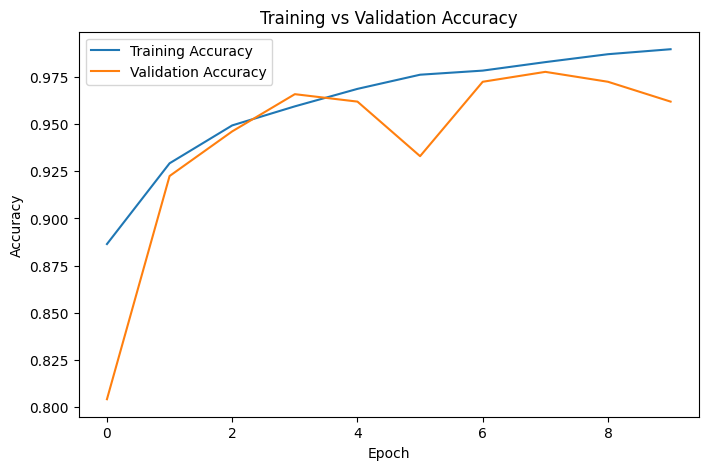

In [70]:
plot_train_accuracy(history=history)

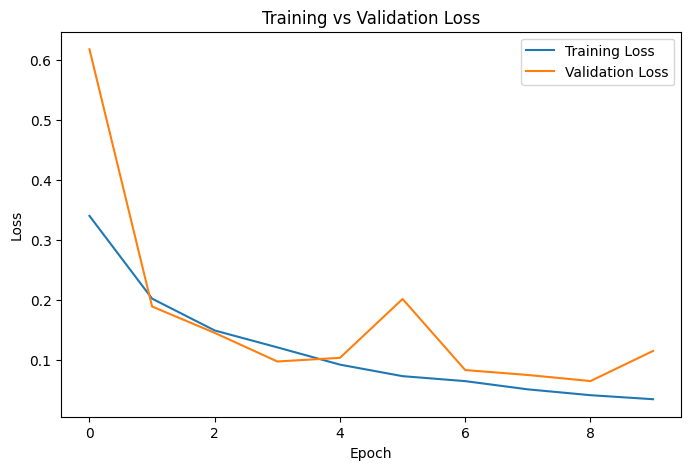

In [72]:
plot_train_loss(history=history)

In [58]:
# Save the model
model.save('CXC1022.keras')
print("Model saved successfully!")

Model saved successfully!


In [59]:
model = tf.keras.models.load_model('CXC1022.keras')

In [60]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 9s 150ms/step - accuracy: 0.9620 - loss: 0.1205
Test Loss: 0.12049616128206253
Test Accuracy: 96.20%


In [61]:
# evaluated against validation dataset
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 173ms/step - accuracy: 0.9619 - loss: 0.1150
Test Loss: 0.11497180908918381
Test Accuracy: 96.19%


2026-05-08 01:02:54.533340: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


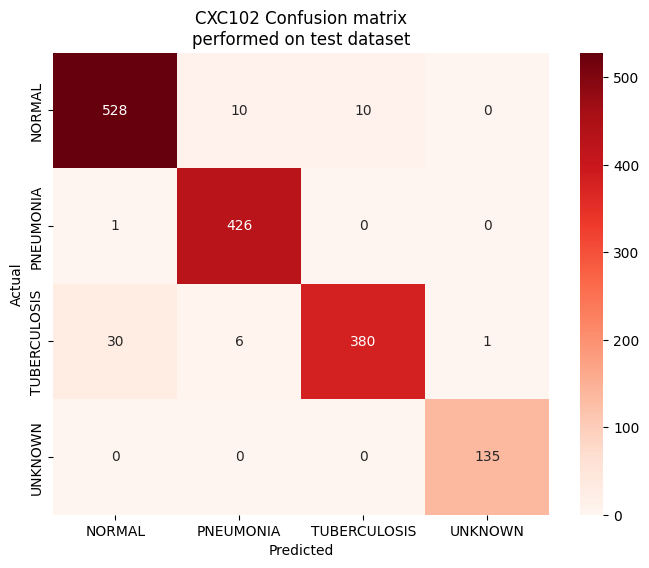

              precision    recall  f1-score   support

      NORMAL       0.94      0.96      0.95       548
   PNEUMONIA       0.96      1.00      0.98       427
TUBERCULOSIS       0.97      0.91      0.94       417
     UNKNOWN       0.99      1.00      1.00       135

    accuracy                           0.96      1527
   macro avg       0.97      0.97      0.97      1527
weighted avg       0.96      0.96      0.96      1527



In [62]:
generate_confusion(
    test_ds, 
    model= model, 
    title= "CXC102 Confusion matrix", 
    subtitle= "performed on test dataset"
)

2026-05-08 01:03:14.047400: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


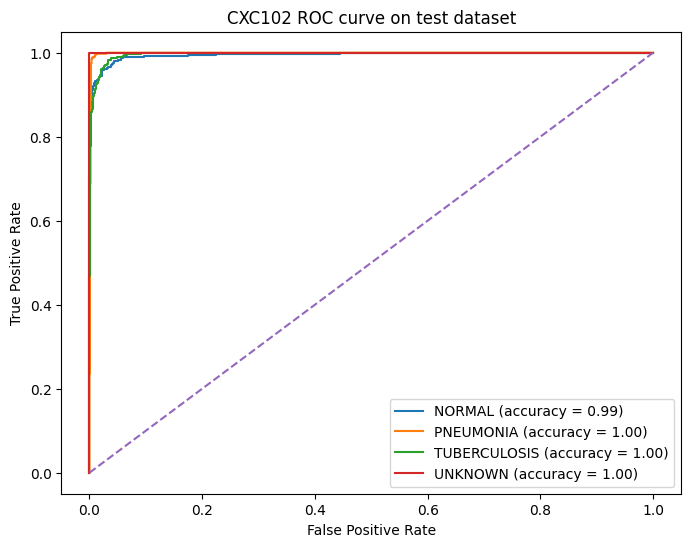

In [63]:
generate_roc_curve(
    test_ds,
    model=model, 
    title="CXC102 ROC curve on test dataset"
    )

2026-05-08 01:03:35.852343: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


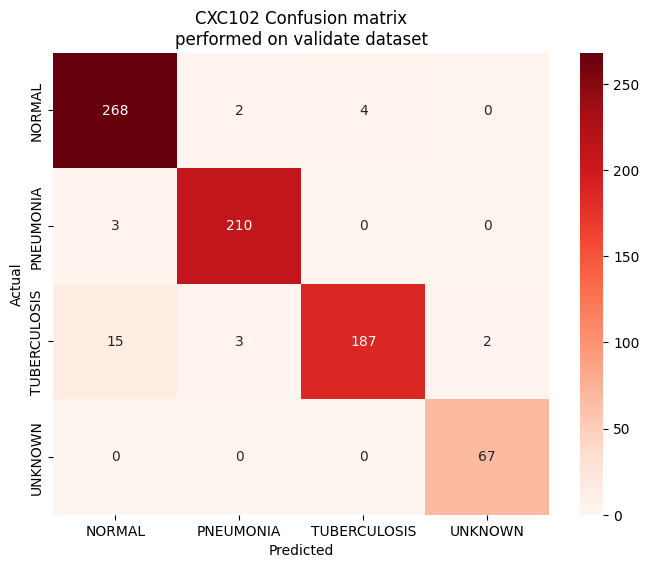

              precision    recall  f1-score   support

      NORMAL       0.94      0.98      0.96       274
   PNEUMONIA       0.98      0.99      0.98       213
TUBERCULOSIS       0.98      0.90      0.94       207
     UNKNOWN       0.97      1.00      0.99        67

    accuracy                           0.96       761
   macro avg       0.97      0.97      0.97       761
weighted avg       0.96      0.96      0.96       761



In [64]:
generate_confusion(
    val_ds, 
    model= model, 
    title= "CXC102 Confusion matrix", 
    subtitle= "performed on validate dataset"
)

2026-05-08 01:03:42.456153: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


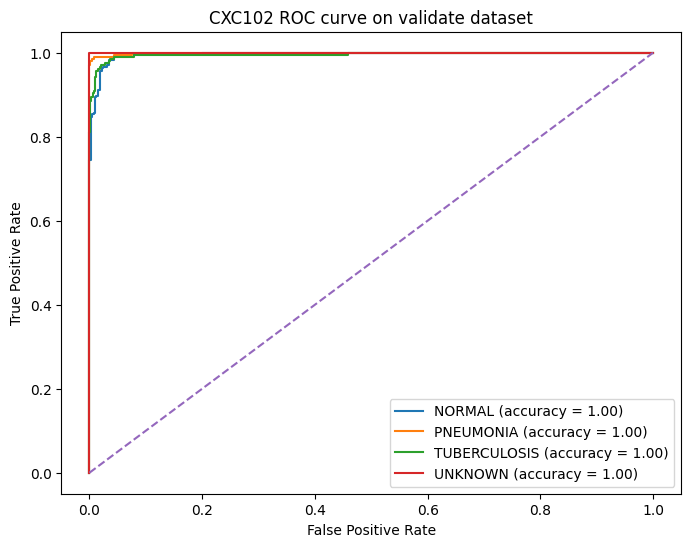

In [65]:
generate_roc_curve(
    val_ds,
    model=model, 
    title="CXC102 ROC curve on validate dataset"
    )